## Interval Analysis

In [19]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = True
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [20]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [21]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [30]:
## TODO: Write the interval analysis for the simple model
def ibp_linear(l, u, weight, bias):
    # split weights by pos + neg to maks sure that
    # the lower and upper bounds are handled correctly
    # lower = lower * pos + upper * neg (maximize negative values, minimize postive values)
    # upper = upper * pos + lower * neg (minimize negative values, maximize postive values)
    w_pos = torch.clamp(weight, min=0)
    w_neg = torch.clamp(weight, max=0)
 
    l_new = l.matmul(w_pos.t()) + u.matmul(w_neg.t()) + bias
    u_new = u.matmul(w_pos.t()) + l.matmul(w_neg.t()) + bias
    return l_new, u_new

def verify_robustness(model, dataloader, epsilons):
    model.eval()
    
    fc1_w = model[1].fc.weight.detach()
    fc1_b = model[1].fc.bias.detach()
    fc2_w = model[1].fc2.weight.detach()
    fc2_b = model[1].fc2.bias.detach()

    # taken from the normalize function
    mean = 0.1307
    std = 0.3081
    
    results = {eps: 0 for eps in epsilons}
    total_samples = len(dataloader.dataset)
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
            batch_size = images.shape[0]
            
            for eps in epsilons:
                # original bounds + normalization
                l = torch.clamp(images - eps, 0.0, 1.0).view(batch_size, -1)
                u = torch.clamp(images + eps, 0.0, 1.0).view(batch_size, -1)
                l = (l - mean) / std
                u = (u - mean) / std
                
                # linear + ReLU + linear layers
                l1, u1 = ibp_linear(l, u, fc1_w, fc1_b)
                l1 = torch.clamp(l1, min=0)
                u1 = torch.clamp(u1, min=0)
                l2, u2 = ibp_linear(l1, u1, fc2_w, fc2_b)
                
                # check outputs
                l_y = l2[torch.arange(batch_size), labels].unsqueeze(1) 
                margins = l_y - u2
                
                # avoid checking case where j == y
                mask = torch.ones_like(margins, dtype=torch.bool)
                mask[torch.arange(batch_size), labels] = False
                min_margins_masked = torch.where(mask, margins, torch.tensor(float('inf')).to(device))
                min_margins, _ = torch.min(min_margins_masked, dim=1)
                
                # bounds pass/get verified if lower bound is >= 0
                verified = (min_margins >= 0).sum().item()
                results[eps] += verified

    for eps in epsilons:
        results[eps] = (results[eps] / float(total_samples)) * 100.0
        print(f"Epsilon: {eps:.4f} -- Verified Accuracy: {results[eps]:.4f}%")
        
    return results

Epsilon: 0.0100 -- Verified Accuracy: 49.5900%
Epsilon: 0.0200 -- Verified Accuracy: 5.3000%
Epsilon: 0.0300 -- Verified Accuracy: 0.2000%
Epsilon: 0.0400 -- Verified Accuracy: 0.0000%
Epsilon: 0.0500 -- Verified Accuracy: 0.0000%
Epsilon: 0.0600 -- Verified Accuracy: 0.0000%
Epsilon: 0.0700 -- Verified Accuracy: 0.0000%
Epsilon: 0.0800 -- Verified Accuracy: 0.0000%
Epsilon: 0.0900 -- Verified Accuracy: 0.0000%
Epsilon: 0.1000 -- Verified Accuracy: 0.0000%


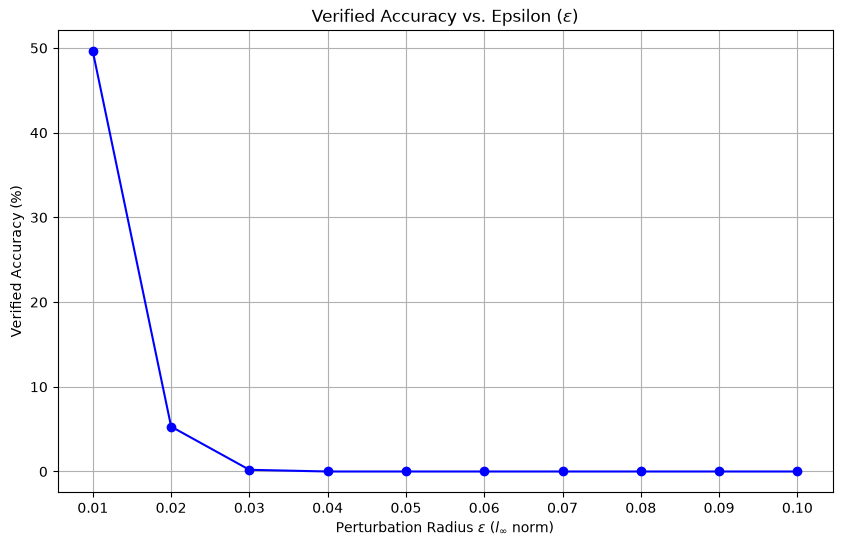

In [32]:
epsilons = np.linspace(0.01, 0.1, 10).tolist()
verified_acc_results = verify_robustness(model, test_loader, epsilons)

plt.figure(figsize=(10, 6))
plt.plot(epsilons, list(verified_acc_results.values()), marker='o', linestyle='-', color='b')
plt.title(r'Verified Accuracy vs. Epsilon ($\epsilon$)')
plt.xlabel(r'Perturbation Radius $\epsilon$ ($l_\infty$ norm)')
plt.ylabel('Verified Accuracy (%)')
plt.grid(True)
plt.xticks(epsilons)
plt.show()